# Scout telemetry: first look

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (14, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["created_at"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df.shape

(24674, 20)

In [2]:
df.head(10)

,created_at,communication_mode,latitude_deg,longitude_deg,heading_deg,course_deg,groundspeed_ms,custom_mode,custom0_arming,wp_num,wp_latitude_deg,wp_longitude_deg,voltage_battery1_v,current_battery1_a,voltage_battery2_v,current_battery2_a,voltage_battery3_v,current_battery3_a,temperature_c,battery_pct
0,2025-07-14 00:20:51.060558+00:00,imt,60.128226,2.216243,6.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,23.54,NaN,NaN,0.2,NaN,NaN,NaN,70.8
1,2025-07-14 01:20:56.346988+00:00,imt,60.128242,2.216200,6.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,23.52,NaN,NaN,0.2,NaN,NaN,NaN,70.4
2,2025-07-14 02:23:06.866079+00:00,imt,60.128273,2.216174,6.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,23.52,NaN,NaN,0.2,NaN,NaN,NaN,70.4
3,2025-07-14 03:05:44.776694+00:00,globalstar,60.128249,2.216252,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
4,2025-07-14 03:24:19.170704+00:00,imt,60.128224,2.216232,6.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,23.50,NaN,NaN,0.2,NaN,NaN,NaN,70.0
5,2025-07-14 04:21:48.351132+00:00,imt,60.128276,2.216140,6.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,23.50,NaN,NaN,0.2,NaN,NaN,NaN,70.0
6,2025-07-14 05:20:52.761082+00:00,imt,60.128209,2.216284,6.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,23.48,NaN,NaN,0.2,NaN,NaN,NaN,69.6
7,2025-07-14 07:39:03.568629+00:00,imt,60.128237,2.216283,346.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,23.48,NaN,NaN,0.3,NaN,NaN,NaN,69.6
8,2025-07-14 07:39:04.852129+00:00,imt,60.129295,2.223341,26.0,NaN,18.6,0.0,0.0,0.0,NaN,NaN,23.48,NaN,NaN,0.3,NaN,NaN,NaN,69.6
9,2025-07-14 07:39:04.882787+00:00,imt,60.250345,2.274866,350.0,NaN,34.2,0.0,0.0,0.0,NaN,NaN,23.47,NaN,NaN,0.3,NaN,NaN,NaN,69.4


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24674 entries, 0 to 24673
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   created_at          24674 non-null  datetime64[us, UTC]
 1   communication_mode  24674 non-null  str                
 2   latitude_deg        24674 non-null  float64            
 3   longitude_deg       24674 non-null  float64            
 4   heading_deg         24594 non-null  float64            
 5   course_deg          21251 non-null  float64            
 6   groundspeed_ms      24594 non-null  float64            
 7   custom_mode         24594 non-null  float64            
 8   custom0_arming      24594 non-null  float64            
 9   wp_num              24594 non-null  float64            
 10  wp_latitude_deg     21251 non-null  float64            
 11  wp_longitude_deg    21251 non-null  float64            
 12  voltage_battery1_v  24587 non-null  float64

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
latitude_deg,24674.0,61.177380,1.136172,0.000000,60.392074,61.093063,62.081119,62.565754
longitude_deg,24674.0,1.788501,0.493469,0.000000,1.537956,1.928049,2.135008,3.146559
heading_deg,24594.0,239.006854,120.215389,0.000000,154.000000,297.225000,338.020000,359.990000
course_deg,21251.0,197.659063,104.776689,0.000000,116.205746,195.603947,298.795300,359.612872
groundspeed_ms,24594.0,0.741238,0.666897,0.000000,0.210950,0.652150,1.094806,34.200000
custom_mode,24594.0,5.043263,6.561235,0.000000,0.000000,0.000000,10.000000,17.000000
custom0_arming,24594.0,0.865414,0.341287,0.000000,1.000000,1.000000,1.000000,1.000000
wp_num,24594.0,0.739001,0.562727,0.000000,0.000000,1.000000,1.000000,3.000000
wp_latitude_deg,21251.0,59.239194,10.274278,0.000000,60.127559,60.460972,61.954740,62.812449
wp_longitude_deg,21251.0,1.624848,0.609661,-0.095888,1.046753,1.809208,2.195952,2.195952


In [5]:
df["communication_mode"].value_counts()

communication_mode
direct        21251
imt            3343
globalstar       80
Name: count, dtype: int64

## What each link sends

Every row is one message received over one of three satellite links. They don't all carry the same fields:

| Field | Starlink (`direct`) | Iridium (`imt`) | Globalstar |
| --- | :---: | :---: | :---: |
| Time, latitude, longitude | ✓ | ✓ | ✓ |
| Heading | ✓ (0.01°) | ✓ (whole degrees) | |
| Course over ground | ✓ | | |
| Speed over ground | ✓ | ✓ (0.2 m/s steps) | |
| Mode, armed, waypoint number | ✓ | ✓ | |
| Waypoint lat/lon | ✓ | | |
| Battery voltage (battery1 V) | ✓ | ✓ | |
| Battery current (battery1 A) | ✓ | | |
| Load current (battery2 A, "thruster") | ✓ | ✓ | |
| battery2 voltage | ✓ | | |
| Solar voltage and current (battery3) | ✓ | | |
| Temperature | ✓ | | |
| `battery_pct` | ✓ | ✓ | ✓ (always 0) |

- **Starlink (`direct`), 21,251 rows.** The full telemetry message. It's switched on in short sessions (median ~10 min, ~10 a day) and sends one message every **15 s** while on. It sent every 1 s on 14 Jul (deployment) and 25 Jul. Only 14 Jul 07:43 to 27 Jul 02:05. It's the only source of solar, battery current and temperature.
- **Iridium (`imt`), 3,343 rows.** A cut-down status message: position, heading, speed, mode, arming, waypoint number, battery voltage, load current and `battery_pct`. One every 2–15 min (mostly 2, 5, 10 or 15), around the clock, every day 14–30 Jul. It's the only link left after 27 Jul.
- **Globalstar, 80 rows.** Basically a position beacon: time, lat, lon, and a `battery_pct` field that is always 0 (a placeholder, not a reading). About one every 4 h, at roughly 03, 07, 11, 15, 19 and 23 UTC.

The table below checks this: it's the % of each link's rows that have a value in each column.

In [6]:
(df.groupby("communication_mode").apply(lambda g: g.notna().mean() * 100)
   .round(0).astype(int).T)

communication_mode,direct,globalstar,imt
created_at,100,100,100
latitude_deg,100,100,100
longitude_deg,100,100,100
heading_deg,100,0,100
course_deg,100,0,0
groundspeed_ms,100,0,100
custom_mode,100,0,100
custom0_arming,100,0,100
wp_num,100,0,100
wp_latitude_deg,100,0,0


## Plots

**Nothing is filtered on this first look.** Every row is plotted wherever it has a value for that column. Things to know when reading the plots:

- `globalstar` rows (80) only carry position and `battery_pct`, and `battery_pct` is always 0. They show up as the zeros in the battery % plot (coloured separately) and on the map. They have no mode, speed, voltage or current, so they can't appear in those plots. The mode plot gives them their own "not reported" lane so you can still see when they arrived.
- 4 rows have position (0, 0), 2 `direct` and 2 `imt`. They stay in the data, but the map window is set around the real track.
- Speed over ground: 4 `imt` readings above 4 m/s (up to 34.2, all on 14 Jul ~07:39). The y-axis is cropped at 4 m/s, so they sit off the top of the plot.
- Vertical gridlines mark midnight UTC every day.

In [7]:
LINK_COLORS = {"direct": "#1f77b4", "imt": "#ff7f0e", "globalstar": "#2ca02c"}
START, END = pd.Timestamp("2025-07-14", tz="UTC"), pd.Timestamp("2025-07-31", tz="UTC")

def daily_axis(ax):
    """One labelled gridline per day, at midnight UTC."""
    ax.set_xlim(START, END)
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    return ax

def time_plot(y, title, ylabel=None):
    fig, ax = plt.subplots()
    for link, g in df.dropna(subset=[y]).groupby("communication_mode"):   # only drops rows without this field
        ax.plot(g.created_at, g[y], ".", ms=2, color=LINK_COLORS[link], label=f"{link} ({len(g)})")
    ax.set_title(title)
    ax.set_ylabel(ylabel or y)
    ax.legend(markerscale=5, loc="best")
    daily_axis(ax)
    return ax

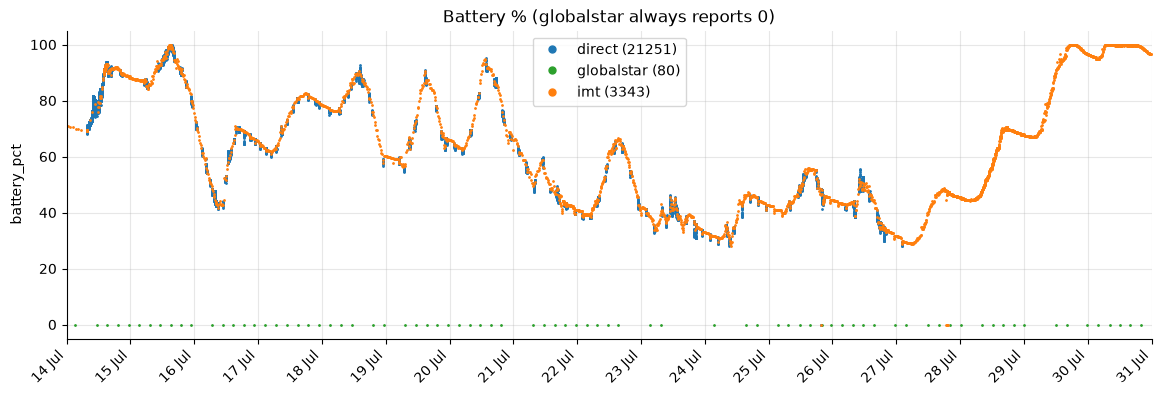

In [8]:
time_plot("battery_pct", "Battery % (globalstar always reports 0)")
plt.show()

### Electrical channels, one plot each
battery1 = battery, battery2 ("thruster" in Tether) = total load, battery3 = solar. Colour shows which link sent the value.

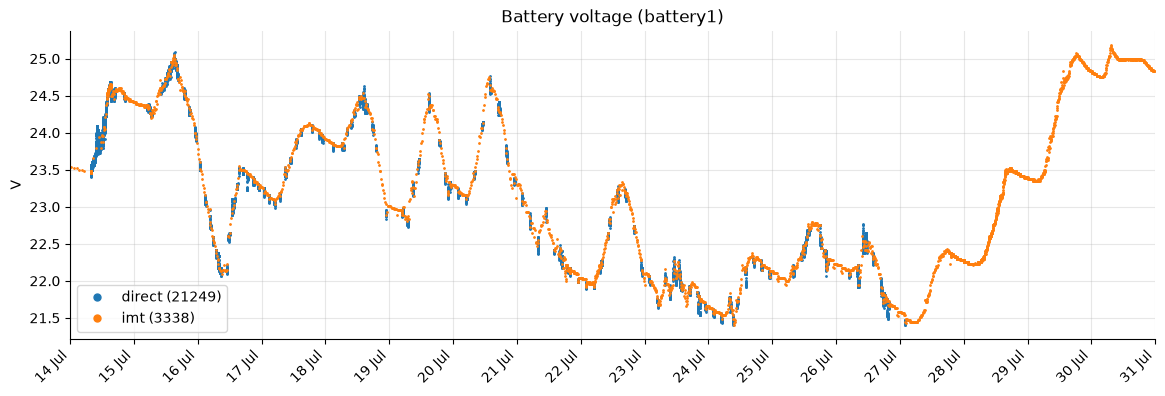

In [9]:
ax = time_plot("voltage_battery1_v", "Battery voltage (battery1)", "V")
plt.show()

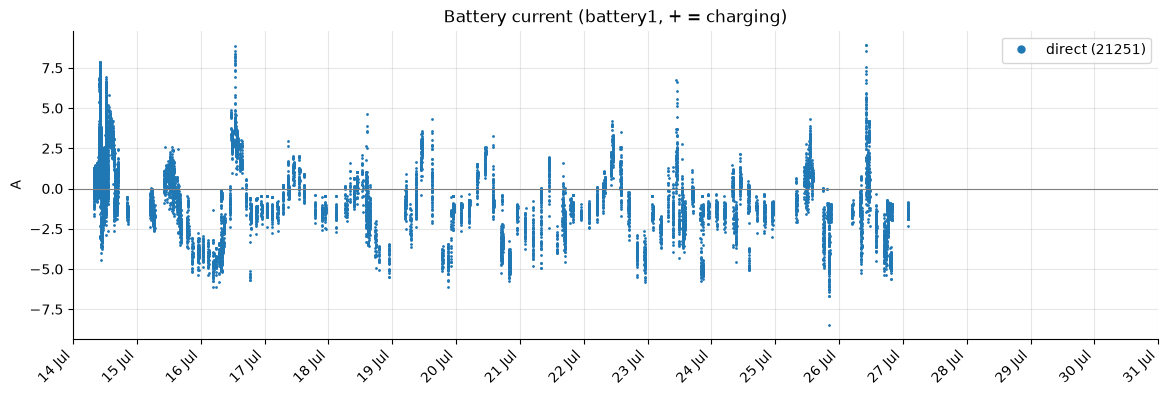

In [10]:
ax = time_plot("current_battery1_a", "Battery current (battery1, + = charging)", "A")
ax.axhline(0, color="grey", lw=0.8)
plt.show()

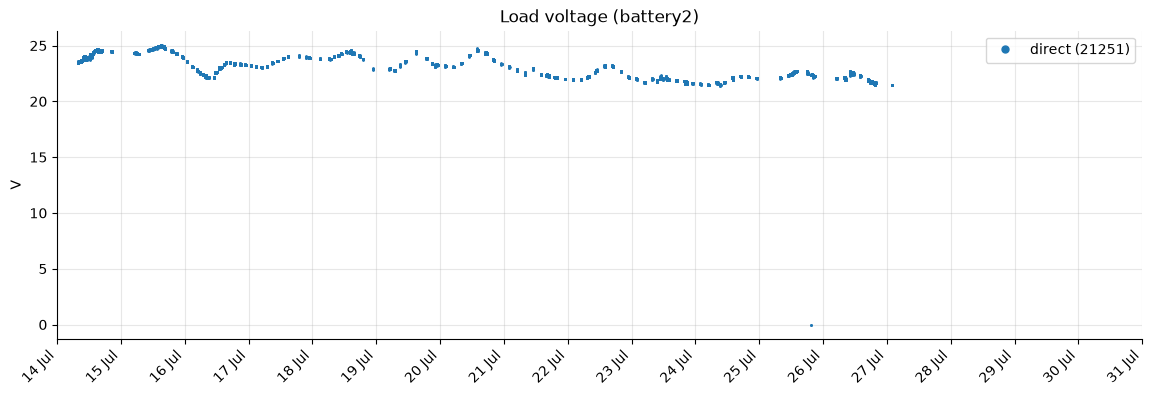

In [11]:
ax = time_plot("voltage_battery2_v", "Load voltage (battery2)", "V")
plt.show()

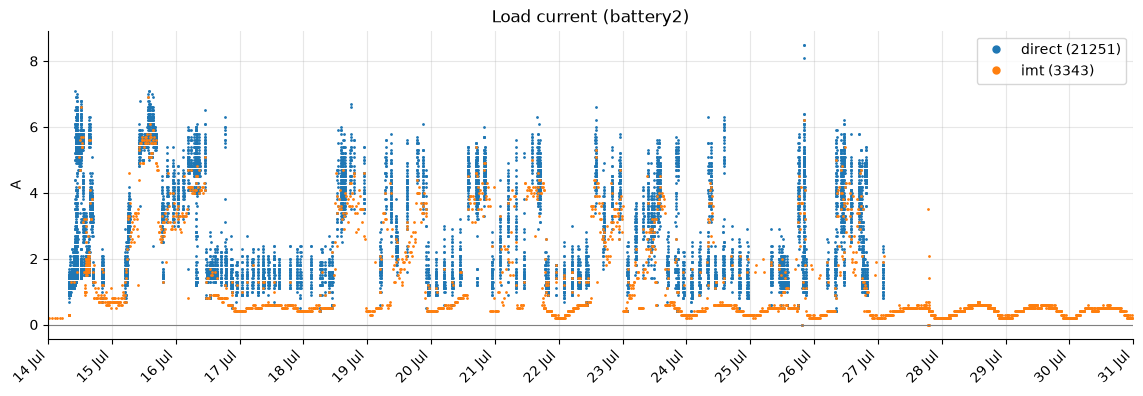

In [12]:
ax = time_plot("current_battery2_a", "Load current (battery2)", "A")
ax.axhline(0, color="grey", lw=0.8)
plt.show()

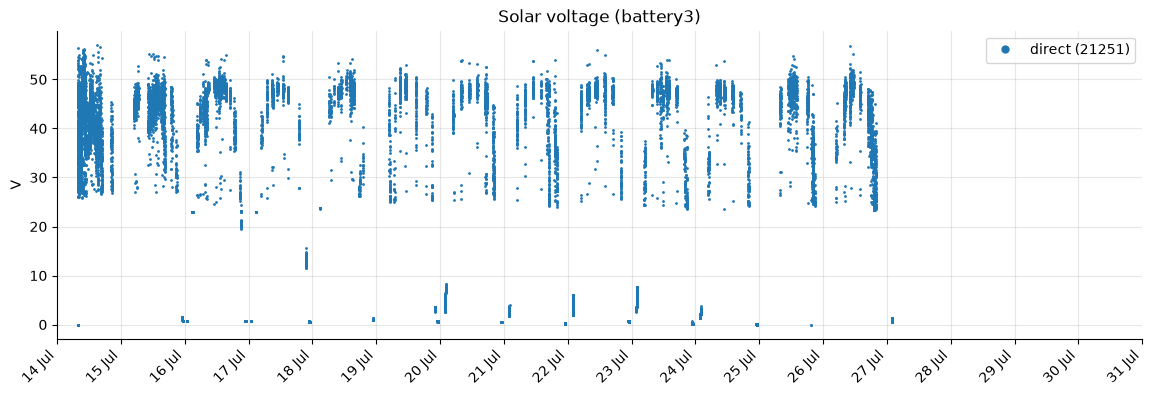

In [13]:
ax = time_plot("voltage_battery3_v", "Solar voltage (battery3)", "V")
plt.show()

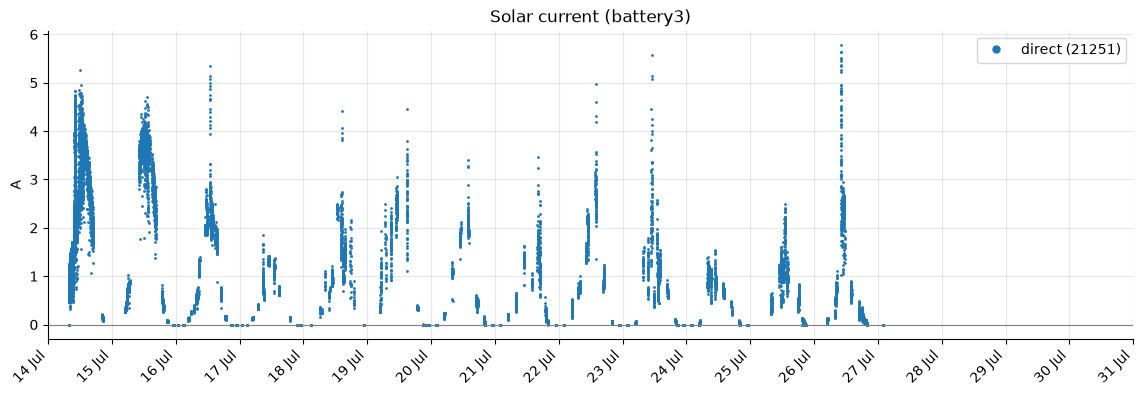

In [14]:
ax = time_plot("current_battery3_a", "Solar current (battery3)", "A")
ax.axhline(0, color="grey", lw=0.8)
plt.show()

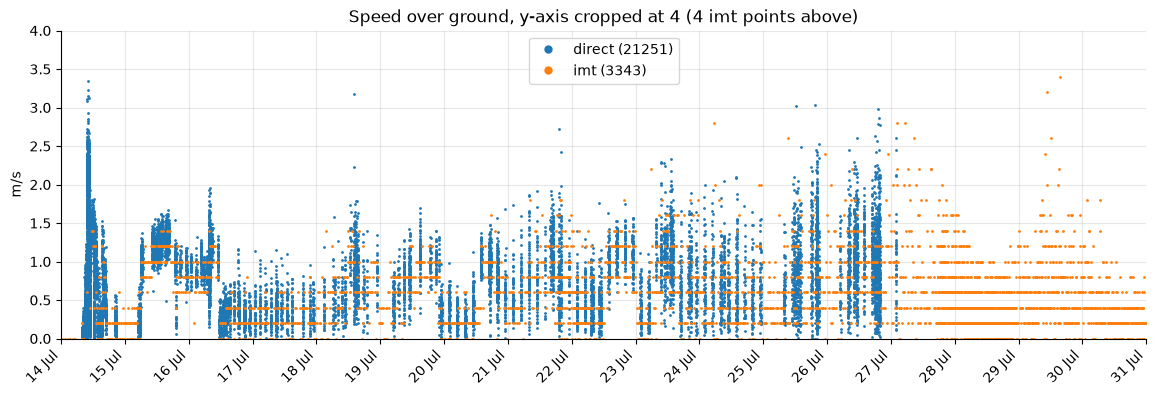

In [15]:
ax = time_plot("groundspeed_ms", "Speed over ground, y-axis cropped at 4 (4 imt points above)", "m/s")
ax.set_ylim(0, 4)
plt.show()

### Autopilot mode
`custom_mode` is the ArduPilot Rover flight-mode number from the MAVLink HEARTBEAT. Values in this data: 0 = MANUAL, 10 = AUTO, 16 = INITIALISING, 17 = not a standard Rover mode (probably a Scout-specific mode, still to confirm). `globalstar` messages don't carry a mode, so they get their own lane.

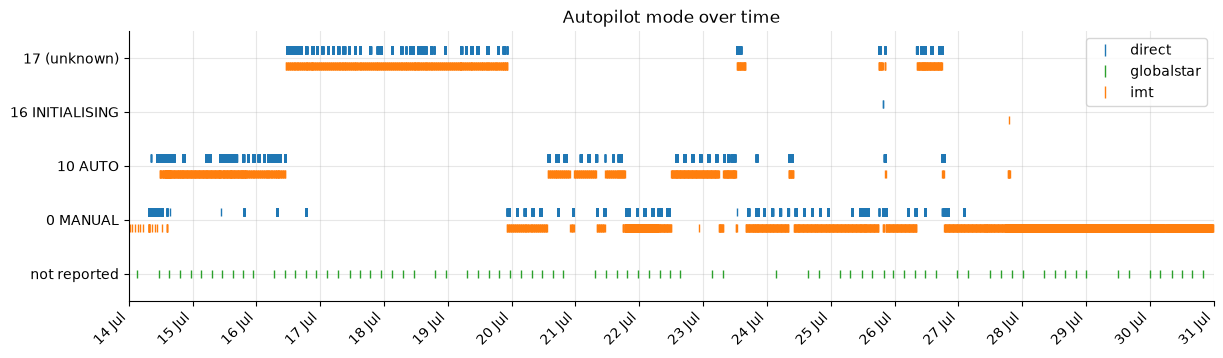

In [16]:
ROVER_MODES = {0: "MANUAL", 1: "ACRO", 3: "STEERING", 4: "HOLD", 5: "LOITER", 6: "FOLLOW",
               7: "SIMPLE", 8: "DOCK", 9: "CIRCLE", 10: "AUTO", 11: "RTL", 12: "SMART_RTL",
               15: "GUIDED", 16: "INITIALISING"}

def mode_label(m):
    if pd.isna(m):
        return "not reported"
    m = int(m)
    return f"{m} {ROVER_MODES.get(m, '(unknown)')}"

order = ["not reported"] + [mode_label(m) for m in sorted(df["custom_mode"].dropna().unique())]
lane = df["custom_mode"].map(mode_label).map({label: i for i, label in enumerate(order)})
fig, ax = plt.subplots(figsize=(14, 3.5))
OFFSET = {"direct": 0.15, "imt": -0.15, "globalstar": 0}   # split each lane so one link doesn't hide the other
for link, g in df.groupby("communication_mode"):
    ax.plot(g.created_at, lane[g.index] + OFFSET[link], "|", ms=6, color=LINK_COLORS[link], label=link)
ax.set_yticks(range(len(order)), order)
ax.set_ylim(-0.5, len(order) - 0.5)
ax.set_title("Autopilot mode over time")
ax.legend(markerscale=1.5, loc="upper right")
daily_axis(ax)
plt.show()

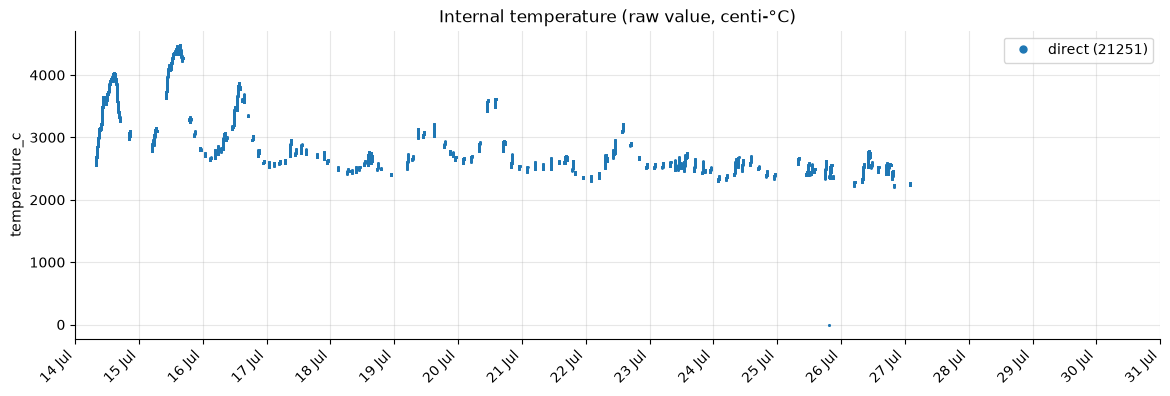

In [17]:
time_plot("temperature_c", "Internal temperature (raw value, centi-°C)")
plt.show()

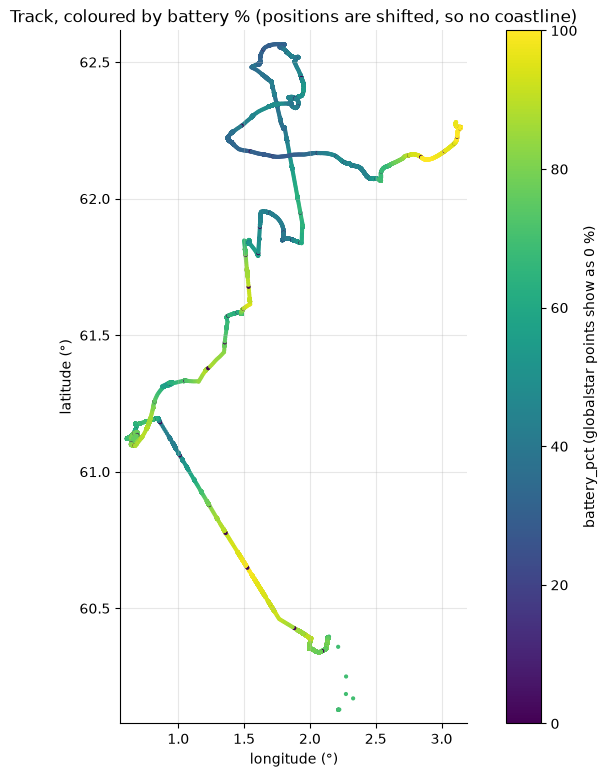

In [18]:
# Map window around the real track; the 4 (0, 0) fixes stay in the data but sit outside it
on_track = df[(df["latitude_deg"] != 0) & (df["longitude_deg"] != 0)]
pad = 0.05
fig, ax = plt.subplots(figsize=(10, 9))
sc = ax.scatter(df.longitude_deg, df.latitude_deg, c=df.battery_pct, s=4, cmap="viridis")
fig.colorbar(sc, ax=ax, label="battery_pct (globalstar points show as 0 %)")
ax.set_xlim(on_track.longitude_deg.min() - pad, on_track.longitude_deg.max() + pad)
ax.set_ylim(on_track.latitude_deg.min() - pad, on_track.latitude_deg.max() + pad)
ax.set_aspect(1 / np.cos(np.radians(on_track.latitude_deg.mean())))   # so 1 km looks the same both ways
ax.set_xlabel("longitude (°)")
ax.set_ylabel("latitude (°)")
ax.set_title("Track, coloured by battery % (positions are shifted, so no coastline)")
plt.show()

### Autopilot mode over the track
Same track, coloured by mode. Globalstar rows have no mode, so they're drawn as small grey crosses. Rarer modes are drawn on top. The 3 INITIALISING rows are reboots, and they report position (0, 0), so they're in the legend but off the map.

The pattern: the long run south-east to north-west at the start is AUTO (14–16 Jul), the western loop is mode 17 (16–19 Jul), the middle section is AUTO again (20–23 Jul), the northern section mixes mode 17 and AUTO, and the eastern tail at the end is MANUAL (drifting, 28–30 Jul).

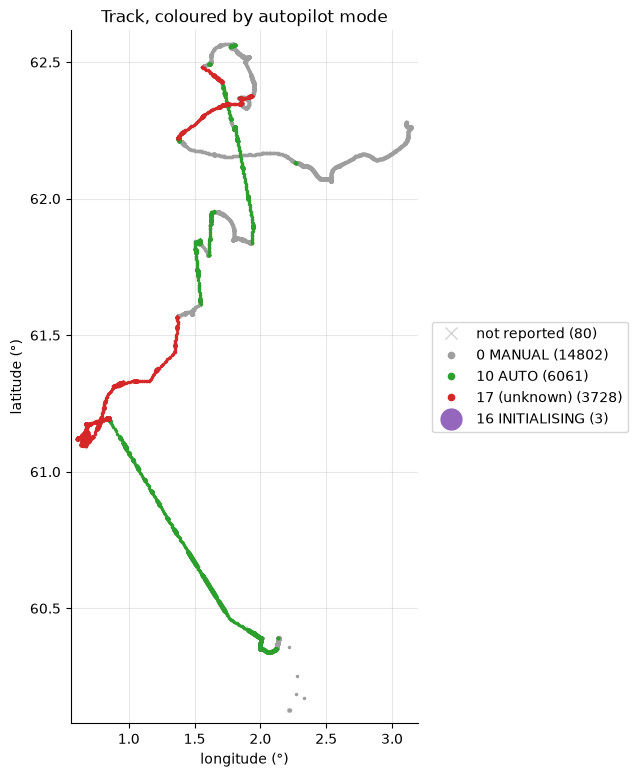

In [19]:
MODE_COLORS = {0: "#9e9e9e", 10: "#2ca02c", 16: "#9467bd", 17: "#d62728"}
fig, ax = plt.subplots(figsize=(10, 9))
gs = df[df.custom_mode.isna()]
ax.plot(gs.longitude_deg, gs.latitude_deg, "x", ms=3, color="lightgrey", label=f"not reported ({len(gs)})")
for m in [0, 10, 17, 16]:
    g = df[df.custom_mode == m]
    ax.plot(g.longitude_deg, g.latitude_deg, ".", ms=3 if m != 16 else 10, color=MODE_COLORS[m],
            label=f"{mode_label(m)} ({len(g)})")
ax.set_xlim(on_track.longitude_deg.min() - pad, on_track.longitude_deg.max() + pad)
ax.set_ylim(on_track.latitude_deg.min() - pad, on_track.latitude_deg.max() + pad)
ax.set_aspect(1 / np.cos(np.radians(on_track.latitude_deg.mean())))
ax.set_xlabel("longitude (°)")
ax.set_ylabel("latitude (°)")
ax.set_title("Track, coloured by autopilot mode")
ax.legend(markerscale=3, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

### Track coloured by speed over ground
Same track, coloured by reported speed over ground. The colour scale stops at 2 m/s so normal speeds are easy to tell apart; anything faster (including the 4 bogus 14 Jul readings) shows as the top colour. Globalstar rows have no speed, so they're drawn as small grey crosses. Points are drawn in time order, so where the track crosses itself the later pass is on top.

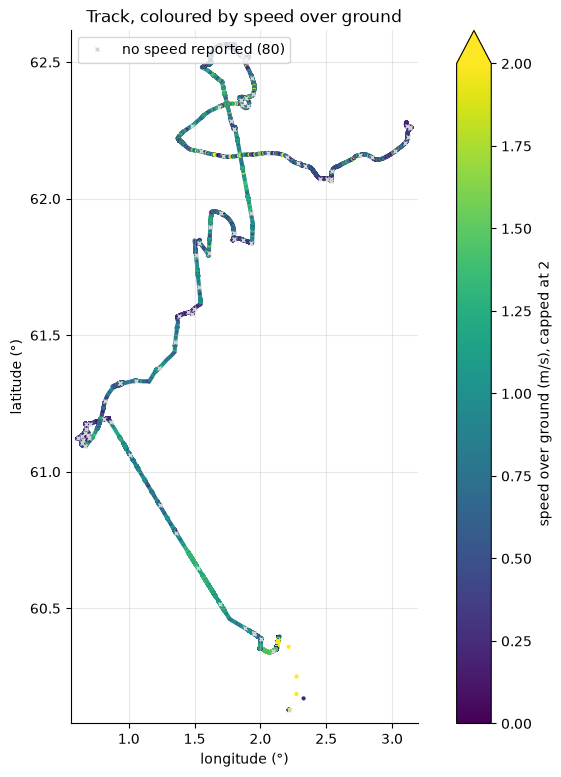

In [20]:
fig, ax = plt.subplots(figsize=(10, 9))
gs = df[df.groundspeed_ms.isna()]
ax.plot(gs.longitude_deg, gs.latitude_deg, "x", ms=3, color="lightgrey", label=f"no speed reported ({len(gs)})")
sp = df.dropna(subset=["groundspeed_ms"]).sort_values("created_at")   # time order, later passes on top
sc = ax.scatter(sp.longitude_deg, sp.latitude_deg, c=sp.groundspeed_ms, s=4, cmap="viridis", vmin=0, vmax=2)
fig.colorbar(sc, ax=ax, label="speed over ground (m/s), capped at 2", extend="max")
ax.set_xlim(on_track.longitude_deg.min() - pad, on_track.longitude_deg.max() + pad)
ax.set_ylim(on_track.latitude_deg.min() - pad, on_track.latitude_deg.max() + pad)
ax.set_aspect(1 / np.cos(np.radians(on_track.latitude_deg.mean())))
ax.set_xlabel("longitude (°)")
ax.set_ylabel("latitude (°)")
ax.set_title("Track, coloured by speed over ground")
ax.legend(loc="upper left")
plt.show()